# Phase 4 - Baseline Machine Learning Model Training

This notebook trains and evaluates baseline Decision Tree, Random Forest, SVM, and Gradient Boosting classifiers using the reproducible Phase 3 train/test data.

The current dataset does not contain URL/domain identifiers, so this experiment evaluates standard phishing classification performance rather than unseen-domain zero-day generalization. No feature selection or extensive hyperparameter tuning is performed.

## Load Preprocessed Data

In [1]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / 'dataset' / 'processed'
RESULTS_DIR = PROJECT_ROOT / 'results'
MODELS_DIR = PROJECT_ROOT / 'models'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

X_train = pd.read_csv(PROCESSED_DIR / 'X_train_tree.csv')
X_test = pd.read_csv(PROCESSED_DIR / 'X_test_tree.csv')
y_train = pd.read_csv(PROCESSED_DIR / 'y_train.csv')['class']
y_test = pd.read_csv(PROCESSED_DIR / 'y_test.csv')['class']

print('Loaded Phase 3 training and testing artifacts.')
print('Training features:', X_train.shape)
print('Testing features:', X_test.shape)

Loaded Phase 3 training and testing artifacts.
Training features: (7737, 31)
Testing features: (3317, 31)


## Verify Dataset Shapes

In [2]:
assert X_train.shape == (7737, 31), X_train.shape
assert X_test.shape == (3317, 31), X_test.shape
assert y_train.shape == (7737,), y_train.shape
assert y_test.shape == (3317,), y_test.shape
assert list(X_train.columns) == list(X_test.columns)
assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0
print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print('y_train shape:', y_train.shape)
print('y_test shape:', y_test.shape)
print('All 31 features are retained; no feature selection is applied.')

X_train shape: (7737, 31)
X_test shape: (3317, 31)
y_train shape: (7737,)
y_test shape: (3317,)
All 31 features are retained; no feature selection is applied.


## Verify Class Labels

In [3]:
# This is the canonical label convention for the verified phishing benchmark schema.
PHISHING_LABEL = -1
LEGITIMATE_LABEL = 1
LABEL_NAMES = {LEGITIMATE_LABEL: 'Legitimate', PHISHING_LABEL: 'Phishing'}

observed_labels = set(pd.concat([y_train, y_test]).unique())
assert observed_labels == {PHISHING_LABEL, LEGITIMATE_LABEL}, observed_labels
assert set(y_train.unique()) == observed_labels
assert set(y_test.unique()) == observed_labels

print('Verified labels:', sorted(observed_labels))
print(f'Positive class for all metrics: {PHISHING_LABEL} ({LABEL_NAMES[PHISHING_LABEL]})')
print(f'Negative class for all metrics: {LEGITIMATE_LABEL} ({LABEL_NAMES[LEGITIMATE_LABEL]})')
print('Training class distribution:')
display(y_train.value_counts().sort_index().rename('count').to_frame())
print('Testing class distribution:')
display(y_test.value_counts().sort_index().rename('count').to_frame())
print('Labels are preserved as -1 and 1; no silent remapping is performed.')

Verified labels: [np.int64(-1), np.int64(1)]
Positive class for all metrics: -1 (Phishing)
Negative class for all metrics: 1 (Legitimate)
Training class distribution:


,count
class,
-1,3428
1,4309


Testing class distribution:


,count
class,
-1,1469
1,1848


Labels are preserved as -1 and 1; no silent remapping is performed.


## Define Evaluation Metrics

The confusion matrix uses the order `[Legitimate (1), Phishing (-1)]`, so its entries are `TN, FP, FN, TP`. Phishing is the positive class for precision, recall, F1, ROC-AUC, FPR, and FNR.

In [4]:
def positive_class_scores(model, X):
    """Return scores where larger values indicate phishing (-1)."""
    if hasattr(model, 'predict_proba'):
        classes = list(model.classes_)
        return model.predict_proba(X)[:, classes.index(PHISHING_LABEL)]
    decision = np.asarray(model.decision_function(X))
    classes = list(model.classes_)
    return decision if classes[1] == PHISHING_LABEL else -decision


def evaluate_model(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    scores = positive_class_scores(model, X_eval)
    matrix = confusion_matrix(y_eval, predictions, labels=[LEGITIMATE_LABEL, PHISHING_LABEL])
    tn, fp, fn, tp = matrix.ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    false_positive_rate = fp / (fp + tn) if (fp + tn) else 0.0
    false_negative_rate = fn / (fn + tp) if (fn + tp) else 0.0
    binary_phishing_target = (y_eval == PHISHING_LABEL).astype(int)
    return {
        'Accuracy': accuracy_score(y_eval, predictions),
        'Precision': precision_score(y_eval, predictions, pos_label=PHISHING_LABEL, zero_division=0),
        'Recall': recall_score(y_eval, predictions, pos_label=PHISHING_LABEL, zero_division=0),
        'F1': f1_score(y_eval, predictions, pos_label=PHISHING_LABEL, zero_division=0),
        'Specificity': specificity,
        'ROC-AUC': roc_auc_score(binary_phishing_target, scores),
        'FPR': false_positive_rate,
        'FNR': false_negative_rate,
        'predictions': predictions,
        'scores': scores,
        'binary_target': binary_phishing_target,
        'confusion_matrix': matrix,
    }


def print_evaluation(name, evaluation):
    tn, fp, fn, tp = evaluation['confusion_matrix'].ravel()
    print(f'\n{name} confusion matrix:')
    print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')
    print(classification_report(
        y_test, evaluation['predictions'],
        labels=[LEGITIMATE_LABEL, PHISHING_LABEL],
        target_names=['Legitimate', 'Phishing'],
        zero_division=0,
    ))

## Decision Tree

In [5]:
models = {}
evaluations = {}

models['Decision Tree'] = DecisionTreeClassifier(random_state=42)
models['Decision Tree'].fit(X_train, y_train)
evaluations['Decision Tree'] = evaluate_model(models['Decision Tree'], X_test, y_test)
print_evaluation('Decision Tree', evaluations['Decision Tree'])


Decision Tree confusion matrix:
TN=1775, FP=73, FN=70, TP=1399
              precision    recall  f1-score   support

  Legitimate       0.96      0.96      0.96      1848
    Phishing       0.95      0.95      0.95      1469

    accuracy                           0.96      3317
   macro avg       0.96      0.96      0.96      3317
weighted avg       0.96      0.96      0.96      3317



## Random Forest

In [6]:
models['Random Forest'] = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
)
models['Random Forest'].fit(X_train, y_train)
evaluations['Random Forest'] = evaluate_model(models['Random Forest'], X_test, y_test)
print_evaluation('Random Forest', evaluations['Random Forest'])


Random Forest confusion matrix:
TN=1805, FP=43, FN=55, TP=1414
              precision    recall  f1-score   support

  Legitimate       0.97      0.98      0.97      1848
    Phishing       0.97      0.96      0.97      1469

    accuracy                           0.97      3317
   macro avg       0.97      0.97      0.97      3317
weighted avg       0.97      0.97      0.97      3317



## SVM

In [7]:
models['SVM'] = Pipeline([
    ('standard_scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, probability=False, random_state=42)),
])
models['SVM'].fit(X_train, y_train)
evaluations['SVM'] = evaluate_model(models['SVM'], X_test, y_test)
print_evaluation('SVM', evaluations['SVM'])
print('The SVM scaler was fitted only inside the pipeline on X_train.')

./venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



SVM confusion matrix:
TN=1797, FP=51, FN=83, TP=1386
              precision    recall  f1-score   support

  Legitimate       0.96      0.97      0.96      1848
    Phishing       0.96      0.94      0.95      1469

    accuracy                           0.96      3317
   macro avg       0.96      0.96      0.96      3317
weighted avg       0.96      0.96      0.96      3317

The SVM scaler was fitted only inside the pipeline on X_train.


## Gradient Boosting

In [8]:
models['Gradient Boosting'] = GradientBoostingClassifier(random_state=42)
models['Gradient Boosting'].fit(X_train, y_train)
evaluations['Gradient Boosting'] = evaluate_model(models['Gradient Boosting'], X_test, y_test)
print_evaluation('Gradient Boosting', evaluations['Gradient Boosting'])


Gradient Boosting confusion matrix:
TN=1789, FP=59, FN=86, TP=1383
              precision    recall  f1-score   support

  Legitimate       0.95      0.97      0.96      1848
    Phishing       0.96      0.94      0.95      1469

    accuracy                           0.96      3317
   macro avg       0.96      0.95      0.96      3317
weighted avg       0.96      0.96      0.96      3317



## Confusion Matrices

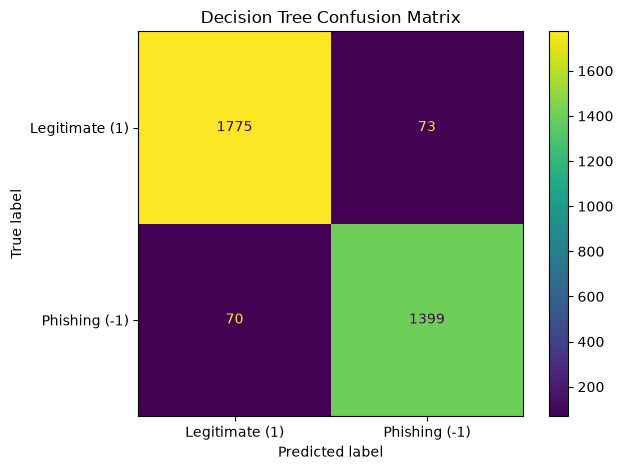

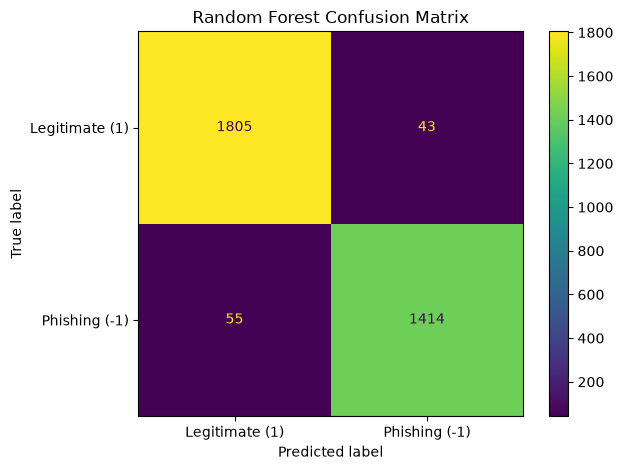

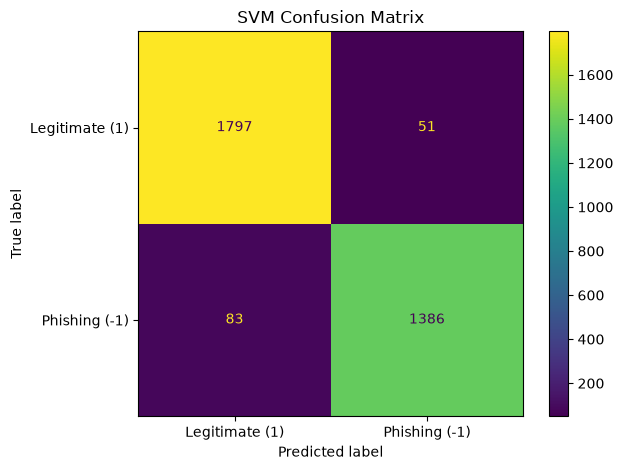

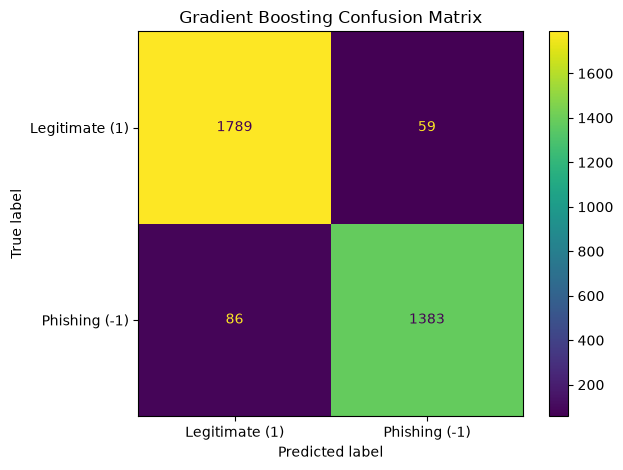

In [9]:
confusion_filenames = {
    'Decision Tree': 'decision_tree_confusion_matrix.png',
    'Random Forest': 'random_forest_confusion_matrix.png',
    'SVM': 'svm_confusion_matrix.png',
    'Gradient Boosting': 'gradient_boosting_confusion_matrix.png',
}

for name, evaluation in evaluations.items():
    display_labels = ['Legitimate (1)', 'Phishing (-1)']
    matrix_display = ConfusionMatrixDisplay(
        confusion_matrix=evaluation['confusion_matrix'],
        display_labels=display_labels,
    )
    matrix_display.plot()
    plt.title(f'{name} Confusion Matrix')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / confusion_filenames[name], dpi=150)
    plt.show()
    plt.close()

## ROC Curves

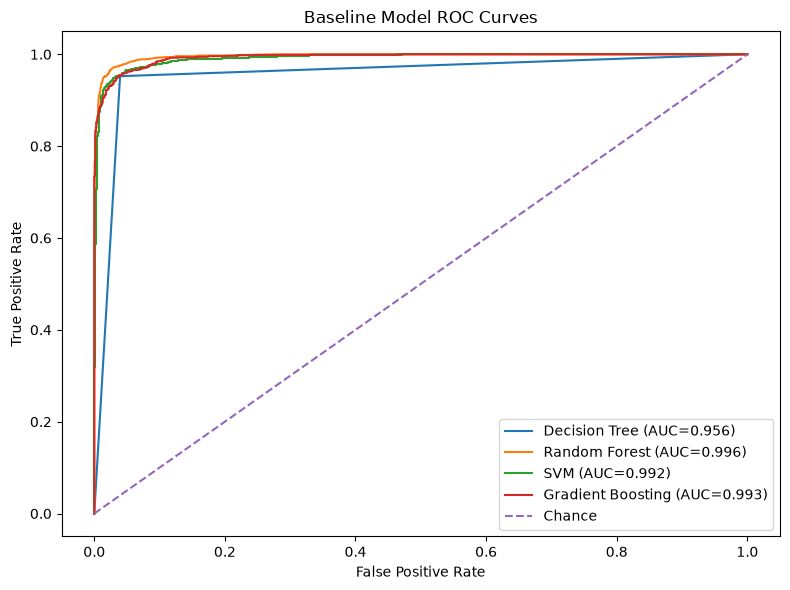

In [10]:
plt.figure(figsize=(8, 6))
for name, evaluation in evaluations.items():
    false_positive_rates, true_positive_rates, _ = roc_curve(
        y_test, evaluation['scores'], pos_label=PHISHING_LABEL
    )
    plt.plot(
        false_positive_rates,
        true_positive_rates,
        label=f"{name} (AUC={evaluation['ROC-AUC']:.3f})",
    )
plt.plot([0, 1], [0, 1], linestyle='--', label='Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Baseline Model ROC Curves')
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'roc_curves.png', dpi=150)
plt.show()
plt.close()

## Model Comparison

,Model,Accuracy,Precision,Recall,F1,Specificity,ROC-AUC,FPR,FNR
0,Random Forest,0.970455,0.970487,0.962560,0.966507,0.976732,0.996104,0.023268,0.037440
1,SVM,0.959602,0.964509,0.943499,0.953889,0.972403,0.991575,0.027597,0.056501
2,Decision Tree,0.956889,0.950408,0.952349,0.951377,0.960498,0.956423,0.039502,0.047651
3,Gradient Boosting,0.956286,0.959085,0.941457,0.950189,0.968074,0.993450,0.031926,0.058543


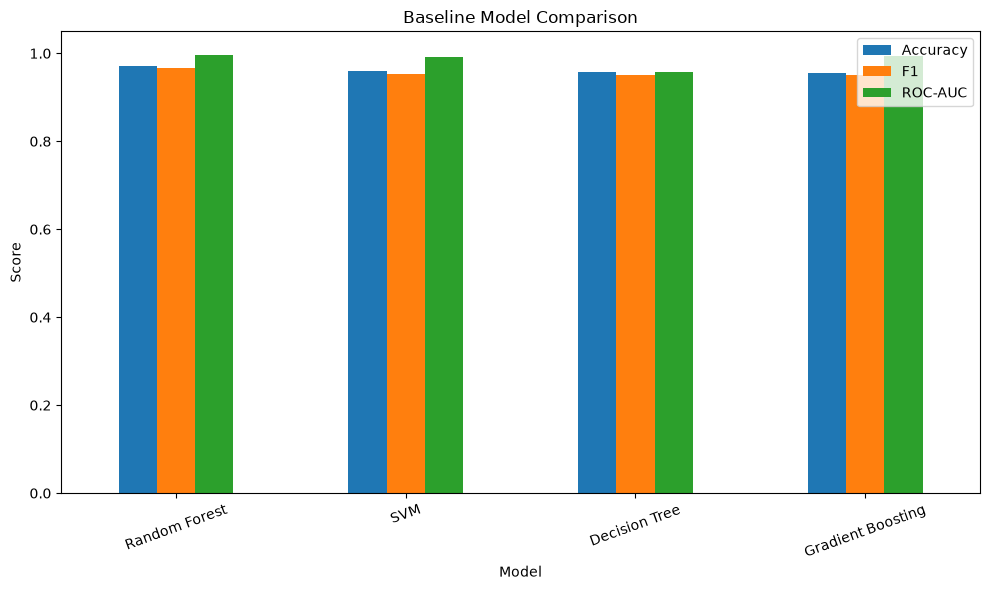

Best model by F1: Random Forest
Best model by ROC-AUC: Random Forest
Best model by accuracy: Random Forest


In [11]:
metric_columns = ['Accuracy', 'Precision', 'Recall', 'F1', 'Specificity', 'ROC-AUC', 'FPR', 'FNR']
comparison = pd.DataFrame({
    name: {metric: evaluation[metric] for metric in metric_columns}
    for name, evaluation in evaluations.items()
}).T.reset_index().rename(columns={'index': 'Model'})
comparison = comparison[['Model'] + metric_columns].sort_values('F1', ascending=False).reset_index(drop=True)
display(comparison)

plt.figure(figsize=(10, 6))
comparison.set_index('Model')[['Accuracy', 'F1', 'ROC-AUC']].plot(kind='bar', ax=plt.gca())
plt.ylim(0, 1.05)
plt.title('Baseline Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'model_comparison.png', dpi=150)
plt.show()
plt.close()

best_f1 = comparison.loc[comparison['F1'].idxmax(), 'Model']
best_auc = comparison.loc[comparison['ROC-AUC'].idxmax(), 'Model']
best_accuracy = comparison.loc[comparison['Accuracy'].idxmax(), 'Model']
print('Best model by F1:', best_f1)
print('Best model by ROC-AUC:', best_auc)
print('Best model by accuracy:', best_accuracy)

## Save Models

In [12]:
model_filenames = {
    'Decision Tree': 'decision_tree_baseline.pkl',
    'Random Forest': 'random_forest_baseline.pkl',
    'SVM': 'svm_baseline.pkl',
    'Gradient Boosting': 'gradient_boosting_baseline.pkl',
}

for name, model in models.items():
    joblib.dump(model, MODELS_DIR / model_filenames[name])
print('Saved baseline models to:', MODELS_DIR)

Saved baseline models to: ./models


## Save Results

In [13]:
comparison.to_csv(RESULTS_DIR / 'baseline_model_results.csv', index=False)
summary = {
    'positive_class': {'label': PHISHING_LABEL, 'meaning': LABEL_NAMES[PHISHING_LABEL]},
    'negative_class': {'label': LEGITIMATE_LABEL, 'meaning': LABEL_NAMES[LEGITIMATE_LABEL]},
    'features_used': int(X_train.shape[1]),
    'train_shape': list(X_train.shape),
    'test_shape': list(X_test.shape),
    'random_state': 42,
    'unseen_domain_evaluation': False,
    'limitation': 'The current dataset does not contain URL/domain identifiers, so this experiment evaluates standard phishing classification performance rather than unseen-domain zero-day generalization.',
    'best_by_f1': best_f1,
    'best_by_roc_auc': best_auc,
    'best_by_accuracy': best_accuracy,
}
(RESULTS_DIR / 'baseline_model_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Saved:', RESULTS_DIR / 'baseline_model_results.csv')
print('Saved:', RESULTS_DIR / 'baseline_model_summary.json')

Saved: ./results\baseline_model_results.csv
Saved: ./results\baseline_model_summary.json


## Phase 4 Conclusion

The four baseline classifiers were trained on the Phase 3 split using all 31 features. Decision Tree, Random Forest, and Gradient Boosting used unscaled features. SVM used a StandardScaler fitted only on training data within a Pipeline.

The reported metrics and figures are calculated from this project dataset and test set. They must not be substituted with accuracy values from the base paper.

The current dataset does not contain URL/domain identifiers, so this experiment evaluates standard phishing classification performance rather than unseen-domain zero-day generalization.

In [14]:
print('Phase 4 summary')
print('Best model by F1:', best_f1)
print('Best model by ROC-AUC:', best_auc)
print('Best model by accuracy:', best_accuracy)
print('Complete comparison table:')
display(comparison)
print('No zero-day or unseen-domain generalization claim is made.')

Phase 4 summary
Best model by F1: Random Forest
Best model by ROC-AUC: Random Forest
Best model by accuracy: Random Forest
Complete comparison table:


,Model,Accuracy,Precision,Recall,F1,Specificity,ROC-AUC,FPR,FNR
0,Random Forest,0.970455,0.970487,0.962560,0.966507,0.976732,0.996104,0.023268,0.037440
1,SVM,0.959602,0.964509,0.943499,0.953889,0.972403,0.991575,0.027597,0.056501
2,Decision Tree,0.956889,0.950408,0.952349,0.951377,0.960498,0.956423,0.039502,0.047651
3,Gradient Boosting,0.956286,0.959085,0.941457,0.950189,0.968074,0.993450,0.031926,0.058543


No zero-day or unseen-domain generalization claim is made.
